# Telco churn: logistic regression (elastic net), the linear benchmark

A linear model on every variable: how well does it predict churn, which variables drive it, and what does a straight line miss?

Rules:
- **Every choice is made on the training set with 5-fold stratified CV**, on the same folds throughout: the new variables, C and l1_ratio, the decision threshold.
- **The hold-out set is scored once, at the end**, after every choice is frozen. It estimates performance; it selects nothing.
- All preprocessing lives inside the sklearn `Pipeline` and is fitted on the rows it is trained on, so the pickle carries it.
- `Customer_ID` and `ethnic` are never features. Only aggregates are shown.

All the logic lives in `src/churn/` (`model.py`, `features.py`); this notebook only calls it.

In [1]:
import pandas as pd
from scipy.special import logit
from sklearn.metrics import ConfusionMatrixDisplay

from churn import eda, model, plots
from churn.config import ROOT, load_config
from churn.data import clean, load_raw, split
from churn.features import add_ratios

cfg = load_config()
e, m = cfg["eda"], cfg["model"]
TARGET = cfg["target"]
ENGINEERED = {**cfg["features"]["ratios"], **cfg["features"]["trend"]}
# Threshold-free metrics decide; precision, recall and F1 come after the threshold is chosen (section 4).
RANKING = ["roc_auc", "pr_auc", "log_loss"]
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

df = clean(load_raw(ROOT / cfg["paths"]["raw_data"]), cfg["cleaning"])
train, test = split(df, TARGET, cfg["test_size"], cfg["seed"])
X, y = model.split_xy(train, cfg)
colors = plots.family_colors(list(cfg["families"]))
print(f"training set: {len(X):,} customers, {X.shape[1]} input variables; "
      f"hold-out: {len(test):,} customers, not used until section 7")


def summary(cv: pd.DataFrame) -> pd.Series:
    return cv.agg(["mean", "sem"]).apply(lambda c: f"{c['mean']:.4f} ± {c['sem']:.4f}")


def at_cut(y_true: pd.Series, proba, cut: float) -> pd.Series:
    """Metrics at one probability cut, and the share of customers it flags as churners."""
    return pd.Series({**model.metrics(y_true, proba, cut), "flagged": (proba >= cut).mean()})

training set: 80,000 customers, 97 input variables; hold-out: 20,000 customers, not used until section 7


## 1. Engineered variables
Seven ratios, defined in `config.yaml` (`features.ratios`, `features.trend`). The first three take the customer's **size** out of a raw signal (heavy users have more minutes, more revenue and more dropped calls, and churn less); the four trend ratios compare the customer with **their own last three months**.

| Variable | Formula | Meaning |
|---|---|---|
| `mou_vs_lifetime` | `mou_Mean / avgmou` | usage against the customer's lifetime average (0.5 = half the usual) |
| `rev_per_mou` | `rev_Mean / mou_Mean` | price paid per minute |
| `drop_blk_rate` | `drop_blk_Mean / attempt_Mean` | share of attempted calls dropped or blocked |
| `mou_vs_avg3` | `mou_Mean / avg3mou` | usage against the last three months: the **recent** drop |
| `rev_vs_avg3` | `rev_Mean / avg3rev` | bill against the last three months |
| `change_mou_pct` | `change_mou / avg3mou` | usage change as a share of the customer's own level |
| `change_rev_pct` | `change_rev / avg3rev` | revenue change as a share of the customer's own level |

`change_mou` and `change_rev` are differences in minutes and dollars, not the percentages the data dictionary describes (EDA section 2c): −100 minutes is a lot for a 200-minute user and little for a 2,000-minute one. Divided by the 3-month average they become the percentage the dictionary promises. A zero denominator gives NaN (no activity, which the denominator column already shows).

First, each ratio alone on the training set (AUC on present values, MI on deciles with Missing as a bin, as in the EDA).

In [2]:
rank = eda.rank_vs_target(train.drop(columns=cfg["exclude"]), TARGET,
                          eda.assign_families(list(X.columns), cfg["families"]), e["n_bins"], cfg["seed"])
ratios = add_ratios(train, ENGINEERED)[[*ENGINEERED, TARGET]]
new = eda.rank_vs_target(ratios, TARGET, pd.Series("engineered", index=list(ENGINEERED)), e["n_bins"], cfg["seed"])
# Where each ratio would sit in the EDA ranking of the 97 original variables.
new["would_rank_mi"] = [int((rank["mi"] > v).sum()) + 1 for v in new["mi"]]
new[["variable", "auc", "direction", "mi", "would_rank_mi", "coverage"]]

,variable,auc,direction,mi,would_rank_mi,coverage
0,change_mou_pct,0.4546,-,0.0120,2,0.9739
1,mou_vs_avg3,0.4543,-,0.0108,2,0.9788
2,mou_vs_lifetime,0.4452,-,0.0086,2,0.9960
3,rev_per_mou,0.5404,+,0.0057,4,0.9802
4,change_rev_pct,0.4926,-,0.0025,12,0.9910
5,drop_blk_rate,0.5209,+,0.0019,24,0.9175
6,rev_vs_avg3,0.4940,-,0.0015,32,0.9963


**Takeaway:** alone, the usage ratios are among the strongest variables in the file.
- `change_mou_pct` and `mou_vs_avg3` would both rank **2nd of 97** by MI (0.0120 and 0.0108), ahead of `mou_vs_lifetime` (0.0086) and far ahead of their sources (`change_mou` 6th, `mou_Mean` 7th in the EDA).
- `rev_per_mou` would rank 4th, `change_rev_pct` 12th, `drop_blk_rate` 24th and `rev_vs_avg3` only 32nd: the bill moves much less than usage.
- Every usage ratio is (−): falling usage goes with churn. A dearer minute (+) and a higher share of failed calls (+) go with churn too.

Univariate strength does not prove added value in a model that already has the source columns: section 2 measures that.

## 2. Do the new variables add information?
Three plain logistic regressions (sklearn's default L2, C = 1, negligible against 64,000 rows per fold) on the same pipeline: clean → (ratios) → signed log (`arcsinh`, which takes zeros and negative values) and median imputation for numbers, one indicator per block of missing columns, one-hot with a `Missing` level for categoricals (levels under 0.5% pooled) → standard scaling of every column → logistic regression.
- **M0**: the 95 original variables.
- **M1**: M0 + the 3 scale-free ratios.
- **M2**: M1 + the 4 trend ratios.

`cross_validate` refits the whole pipeline on each fold, so medians and scales never see the validation customers. Same folds for all three, so the differences are **paired**: their standard error is far smaller than either model's. Values are mean ± standard error over the 5 folds.

In [3]:
lr = model.baseline(cfg)
cv0 = model.cv_metrics(model.build_pipeline(cfg, lr, ratios=False, trend=False), X, y, cfg)
cv1 = model.cv_metrics(model.build_pipeline(cfg, lr, trend=False), X, y, cfg)
cv2 = model.cv_metrics(model.build_pipeline(cfg, lr), X, y, cfg)
pd.DataFrame({"M0 original": summary(cv0[RANKING]), "M1 + ratios": summary(cv1[RANKING]),
              "M2 + trend": summary(cv2[RANKING]), "M1 − M0 (paired)": summary((cv1 - cv0)[RANKING]),
              "M2 − M1 (paired)": summary((cv2 - cv1)[RANKING])})

,M0 original,M1 + ratios,M2 + trend,M1 − M0 (paired),M2 − M1 (paired)
roc_auc,0.6431 ± 0.0017,0.6434 ± 0.0015,0.6443 ± 0.0018,0.0003 ± 0.0002,0.0009 ± 0.0003
pr_auc,0.6287 ± 0.0017,0.6292 ± 0.0013,0.6305 ± 0.0015,0.0006 ± 0.0004,0.0013 ± 0.0002
log_loss,0.6615 ± 0.0007,0.6613 ± 0.0007,0.6608 ± 0.0008,-0.0002 ± 0.0001,-0.0005 ± 0.0002


**Takeaway:** the new variables add little to a linear model.
- The 3 scale-free ratios: +0.0003 ± 0.0002 ROC-AUC, within the noise. The 4 trend ratios: **+0.0009 ± 0.0003** ROC-AUC and −0.0005 ± 0.0002 log-loss, real (3 SE) but small.
- This is expected. On the signed-log scale a ratio is a difference, asinh(a) − asinh(b) ≈ log a − log b, which the model can already build from its two source columns with opposite coefficients. The trend ratios add a little more because `change_mou` is itself a difference that can be negative, so its share of the customer's level is not a difference of logs.
- They stay: both models get the same inputs, and each ratio reads as one business sentence. Their value is measured where a model can use them non-linearly: `03_xgboost`, section 2.

## 3. Elastic net: C and l1_ratio chosen by CV
`LogisticRegressionCV` (solver `saga`) walks 19 values of C from 10⁻⁴ (almost every coefficient zero) to 100 (no penalty at all) for each l1_ratio in {0.2, 0.5, 0.8}, on the same 5 folds, scored by **log-loss** (a proper scoring rule: it rewards calibrated probabilities). **The configuration with the best mean CV log-loss is the model.** Each path is warm-started from the previous C, so the 57 configurations cost about one fit per fold and l1_ratio.
- **Why elastic net and not the lasso**: with groups of near-duplicates (the 30-variable usage group, `totrev`/`adjrev` at ρ 0.996) the lasso keeps one twin almost at random; the L2 part keeps correlated variables together and shares the credit.
- **Why the path goes past C = 1**: so that the best value is not on the edge of what was tried.
- **Known compromise**: inside `LogisticRegressionCV` the preprocessing (medians, scales, category frequencies) is fitted once on the whole training set. These statistics do not use churn, so the leak is negligible at 80,000 rows; every comparison below uses `cross_validate` on the full pipeline, which refits everything per fold.

encoded columns: 197; max saga iterations: 150 (limit 1000)


,C,loss,se,n_nonzero,gap_to_best
l1_ratio,,,,,
0.2000,100.0000,0.6608,0.0007,197.0000,0.0000
0.5000,100.0000,0.6608,0.0007,197.0000,0.0000
0.8000,100.0000,0.6608,0.0007,197.0000,0.0000


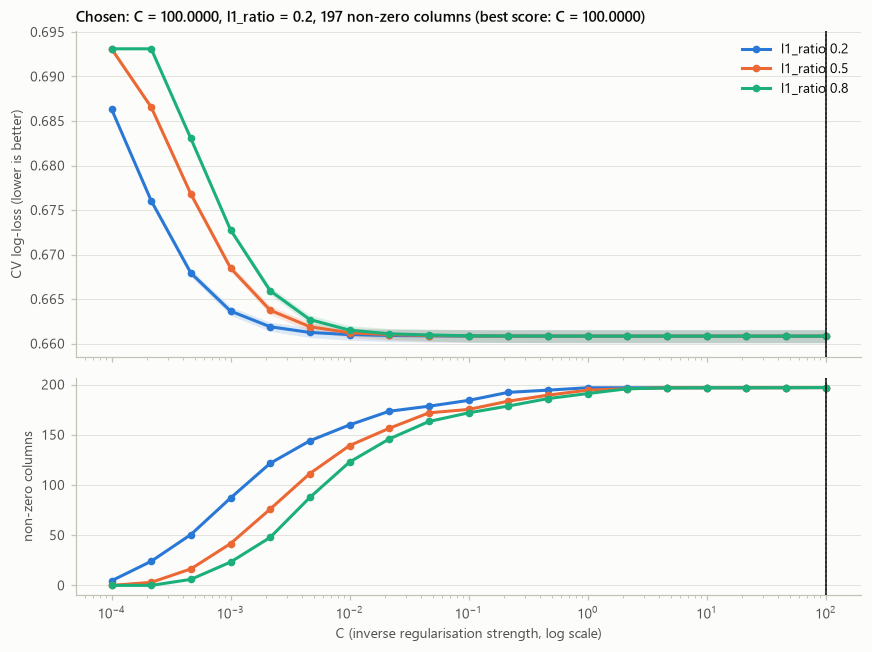

In [4]:
search = model.build_pipeline(cfg, model.elastic_net_cv(cfg)).fit(X, y)
path = model.cv_path(search[-1])
best = path.loc[path["score"].idxmax()]
print(f"encoded columns: {search['scale'].n_features_in_}; max saga iterations: {search[-1].n_iter_.max()} "
      f"(limit {m['elastic_net']['max_iter']})")
fig = plots.plot_cv_path(path, best, best)
# The best C for each l1_ratio, and how far each is from the overall best.
per_ratio = path.loc[path.groupby("l1_ratio")["score"].idxmax()].set_index("l1_ratio")
per_ratio.assign(loss=-per_ratio["score"], gap_to_best=best["score"] - per_ratio["score"])[["C", "loss", "se", "n_nonzero", "gap_to_best"]]

**Takeaway: the penalty does not help; the best model is the one with (almost) no penalty.**
- The CV log-loss is **flat from C ≈ 0.1 to C = 100** (0.66083–0.66088 for all three l1_ratios, differences under 0.0001 against an SE of 0.0007). Below C ≈ 0.01 it rises quickly: there the penalty starts removing real signal (at C = 10⁻⁴ almost every coefficient is zero).
- The best mean score is at C = 100 with l1_ratio 0.2, by a margin of 10⁻⁵: any C above 0.1 gives the same model quality, and at C = 100 all 197 encoded columns are kept. With 80,000 customers and ~200 columns there is little variance for a penalty to remove.
- So the elastic net on every variable ends up as a plain logistic regression: that is a result of the CV, not an assumption. Every fit converged (at most 150 saga iterations of 1,000).

## 4. The decision threshold: more recall, F1 as the referee
A probability becomes a decision at a cut. At 0.5 precision and recall are about equal; to **catch more churners** the cut moves down, and **F1** (the harmonic mean of precision and recall) says how far: the cut is the one with the highest F1 on the **out-of-fold** training predictions (each customer scored by the model fitted on the other folds, so no customer scores itself).

Caveat: on this ~50% sample, flagging every customer already gives F1 = 2 × 0.5 / 1.5 ≈ 0.66, so the F1-best cut flags many customers. The share flagged is shown next to every cut, and section 7 gives the campaign view (the riskiest 10–20%).

In [5]:
final_pipe = model.build_pipeline(cfg, model.elastic_net(cfg, best["C"], best["l1_ratio"]))
cv_lr = model.cv_metrics(final_pipe, X, y, cfg)
oof = model.oof_proba(final_pipe, X, y, cfg)
threshold = model.best_f1_threshold(y, oof)
print("CV (mean ± SE over folds):", summary(cv_lr[RANKING]).to_dict())
print("for config.yaml, model.logistic_final:",
      {"C": float(best["C"]), "l1_ratio": float(best["l1_ratio"]), "threshold": round(threshold, 4)})
pd.DataFrame({"cut 0.50": at_cut(y, oof, 0.5), f"cut {threshold:.3f} (max F1)": at_cut(y, oof, threshold)})

CV (mean ± SE over folds): {'roc_auc': '0.6441 ± 0.0016', 'pr_auc': '0.6305 ± 0.0014', 'log_loss': '0.6608 ± 0.0007'}
for config.yaml, model.logistic_final: {'C': 100.0, 'l1_ratio': 0.2, 'threshold': 0.3387}


,cut 0.50,cut 0.339 (max F1)
roc_auc,0.6442,0.6442
pr_auc,0.6304,0.6304
log_loss,0.6608,0.6608
precision,0.6061,0.5202
recall,0.5793,0.9381
f1,0.5924,0.6693
flagged,0.4737,0.8937


**Takeaway:** CV ROC-AUC **0.644 ± 0.002**, log-loss 0.661. At 0.5 the model has precision 0.61 and recall 0.58 (F1 0.59). The F1-best cut is **0.339**: recall rises to **0.94**, precision falls to 0.52 and F1 rises to **0.67**.
- The price: this cut flags **89% of customers**. Flagging everyone would give precision 0.50, recall 1 and F1 0.66, almost the same. With a ranking this weak (ROC-AUC 0.64), F1 is maximised by flagging almost everyone: the linear model separates churners from stayers only a little.

## 5. What the model uses
**Reading a coefficient.** Every column is standardised, so a coefficient β is the change in the **log-odds** of churn when the variable rises by **one standard deviation** (on the signed-log scale, so roughly a fixed percentage increase of the raw value), **holding every other variable fixed**. Its exponential is an **odds ratio**: OR 1.20 means the odds of churn are 20% higher, OR 0.80 20% lower.

**Importance of a variable** = the **mean |contribution| to the log-odds** across customers, where the contribution is coefficient × standardised value, summed over the variable's columns (all levels of a categorical, its missing indicator kept apart). For a linear model this is exactly the SHAP value, so the same table gives the single-customer explanation. (+) / (−): a higher value goes with more / less churn; categoricals have no single direction.

113 input variables, 113 with a non-zero coefficient; the top 21 carry 50% of the total importance, the top 47 carry 80%


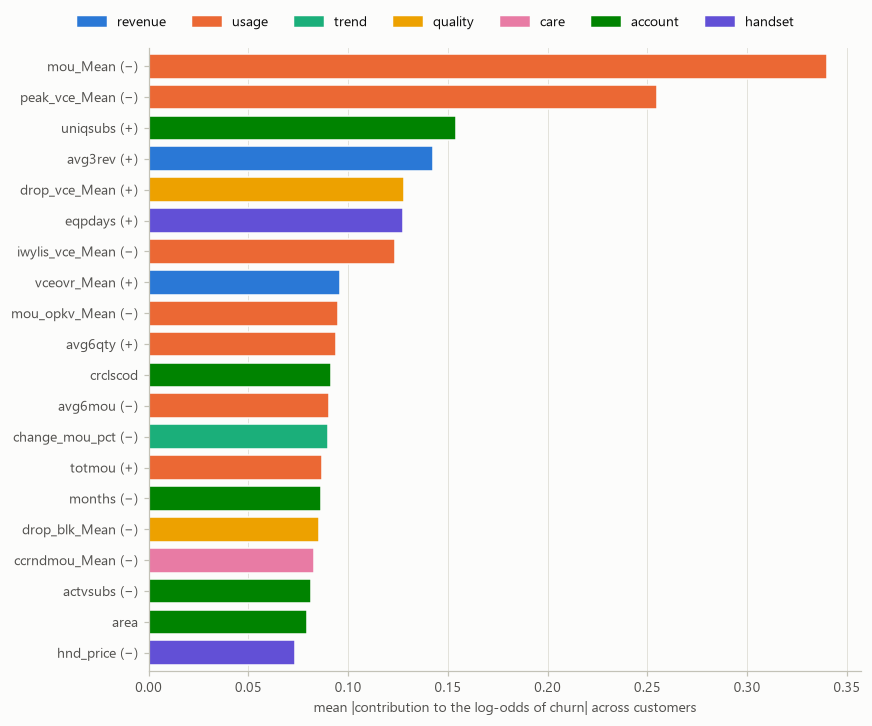

In [6]:
final = final_pipe.fit(X, y)
imp = model.importance(final, X, cfg["families"])
share = imp["importance"].cumsum() / imp["importance"].sum()
n50, n80 = int((share < 0.5).sum()) + 1, int((share < 0.8).sum()) + 1
print(f"{len(imp)} input variables, {imp['selected'].sum()} with a non-zero coefficient; "
      f"the top {n50} carry 50% of the total importance, the top {n80} carry 80%")
fig = plots.plot_importance(imp, colors, 20)

In [7]:
# The top 15 with their coefficient and odds ratio per standard deviation (one-column variables only; a categorical
# has one coefficient per level, so only its importance is shown).
coefs = model.coefficients(final)
single = coefs.groupby("variable").filter(lambda g: len(g) == 1).set_index("variable")[["coef", "or_per_sd"]]
fam = imp.groupby("family")["importance"].sum().sort_values(ascending=False)
print("share of the importance by family:", (fam / fam.sum()).round(2).to_dict())
imp.head(15)[["family", "importance", "direction"]].join(single).assign(rank=range(1, 16))

share of the importance by family: {'usage': 0.43, 'revenue': 0.13, 'account': 0.11, 'household': 0.11, 'handset': 0.08, 'quality': 0.06, 'trend': 0.05, 'care': 0.03}


,family,importance,direction,coef,or_per_sd,rank
variable,,,,,,
mou_Mean,usage,0.3402,-,-0.4797,0.6189,1
peak_vce_Mean,usage,0.2546,-,-0.3403,0.7116,2
uniqsubs,account,0.1540,+,0.1749,1.1912,3
avg3rev,revenue,0.1427,+,0.1900,1.2093,4
drop_vce_Mean,quality,0.1280,+,0.1512,1.1632,5
eqpdays,handset,0.1275,+,0.1848,1.2030,6
iwylis_vce_Mean,usage,0.1236,-,-0.1407,0.8687,7
vceovr_Mean,revenue,0.0957,+,0.1052,1.1110,8
mou_opkv_Mean,usage,0.0951,-,-0.1210,0.8860,9


**Takeaway: the model keeps every variable, and its largest coefficients describe usage.**
- All 113 input variables (97 original, 7 ratios, 9 missing indicators) keep a non-zero coefficient. Importance is spread out: the top 21 carry half of it, the top 47 carry 80%.
- **Reading the coefficients**, at equal values of everything else: one standard deviation more of current minutes (`mou_Mean`) multiplies the odds of churn by 0.62 (−38%). One more standard deviation multiplies them by 1.19 for subscribers in the household (`uniqsubs`), 1.20 for handset age (`eqpdays`), 1.16 for dropped voice calls (`drop_vce_Mean`) and 1.11 for voice overage revenue (`vceovr_Mean`). The usage change as a share of the customer's own level (`change_mou_pct`) multiplies them by 0.88.
- **Usage takes 43% of the importance, but much of it cancels out.** With no penalty, near-duplicates split one signal into large coefficients of opposite sign: `mou_Mean` (−) against `totmou` (+), `avg6mou` (−) against `avg6qty` (+), `drop_vce_Mean` (+) against `drop_blk_Mean` (−). These coefficients are offsets between twins, not business effects: read the usage family as one driver.
- **The robust signals** are the ones with no twin to offset them:
  - more subscribers than active lines (`uniqsubs` +, `actvsubs` −);
  - an old handset (`eqpdays` +) and a cheap one (`hnd_price` −);
  - voice overage (`vceovr_Mean` +);
  - falling usage (`change_mou_pct` −);
  - credit class and area.
- Tenure (`months`) is only 15th, with a negative sign: a straight line cannot place its peak (next section).

## 6. What a straight line misses
For the strongest variables, the black line is what the logistic regression can draw: its contribution against the variable's value, monotonic by construction (a straight line on the signed-log scale). The coloured line is the **observed** churn, as log-odds against the average, per value (or per band of 5% of customers). The observed line looks at each variable alone while the model holds the others fixed, so only the **shape** is compared, not the height.

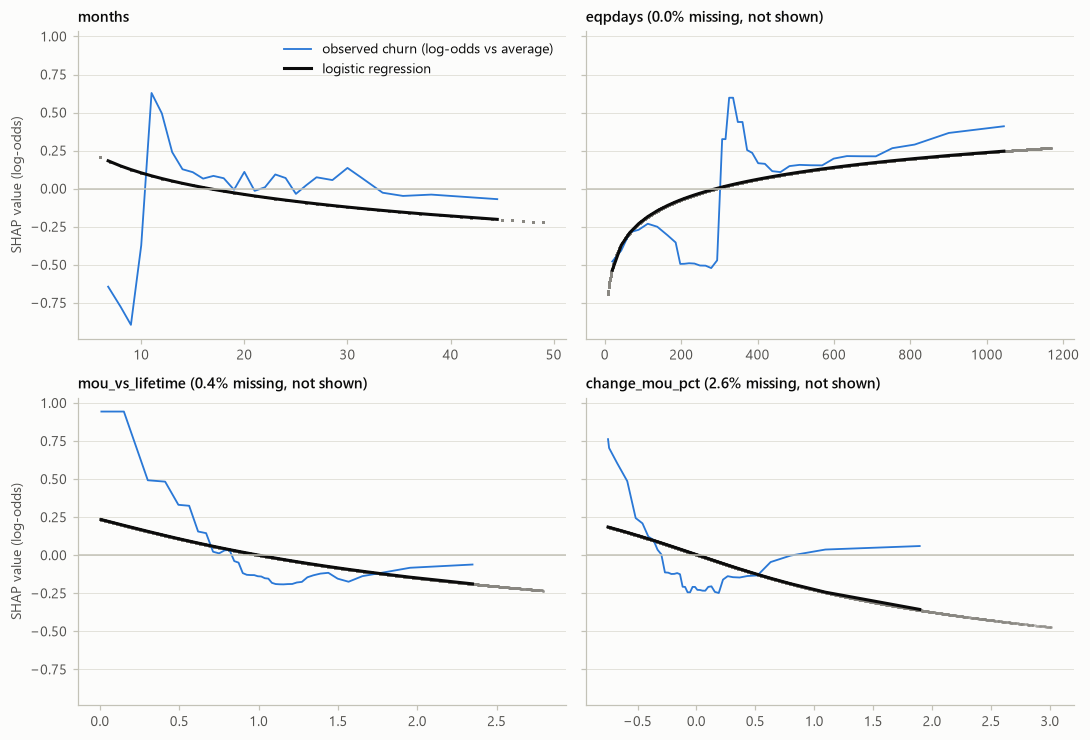

In [8]:
contrib = model.contributions(final, X)
values = final[:2].transform(X)  # the model's inputs before encoding: cleaned values and the ratios
shape_vars = ["months", "eqpdays", "mou_vs_lifetime", "change_mou_pct"]


def observed(v: str) -> pd.Series:
    band = values[v] if values[v].nunique() <= 60 else pd.qcut(values[v], 20, duplicates="drop")
    return logit(y.groupby(band, observed=True).transform("mean")) - logit(y.mean())


fig = plots.plot_dependence(contrib, values, shape_vars, label="logistic regression",
                            curves={"observed churn (log-odds vs average)": pd.DataFrame({v: observed(v) for v in shape_vars})})

**Takeaway: the data have peaks, steps and plateaus; a straight line draws none of them.**
- **Tenure**: observed churn dips at 7–9 months (−0.6 to −0.9 log-odds against the average) and jumps to a **peak at 11–12 months** (+0.5 to +0.6). The model can only draw a gentle downward slope.
- **Handset age**: observed churn stays low up to ~280 days (−0.25 to −0.5) and **jumps by about +1 log-odds at 300–340 days**. The model draws a smooth rising curve, so the step falls nowhere.
- **Usage against own history**: risk rises steeply as usage collapses (+0.95 at zero usage) and is flat once usage reaches about 75% of the usual. The model's line is too flat at the bottom and keeps sloping where the data are flat.
- **Usage change**: the observed effect is a V, with the lowest risk at no change and risk rising again for large increases. The model keeps lowering the risk as usage grows.
- **This is information lost.** The model cannot use the 11–12-month peak or the 300-day step, two of the strongest signals in the file. A model that learns shapes is needed: `03_xgboost` measures how much it buys.

## 7. Hold-out set: scored once, at the chosen threshold
Everything above is frozen: the variables, C, l1_ratio and the cut. The 20,000 hold-out customers (stratified, never looked at before) are scored by the pipeline fitted on the whole training set.

In [9]:
X_test, y_test = model.split_xy(test, cfg)
proba = final.predict_proba(X_test)[:, 1]
pd.DataFrame({"hold-out": at_cut(y_test, proba, threshold), "CV out-of-fold (train)": at_cut(y, oof, threshold),
              "hold-out at 0.5": at_cut(y_test, proba, 0.5)})

,hold-out,CV out-of-fold (train),hold-out at 0.5
roc_auc,0.6448,0.6442,0.6448
pr_auc,0.6330,0.6304,0.6330
log_loss,0.6602,0.6608,0.6602
precision,0.5197,0.5202,0.6072
recall,0.9410,0.9381,0.5792
f1,0.6696,0.6693,0.5929
flagged,0.8973,0.8937,0.4728


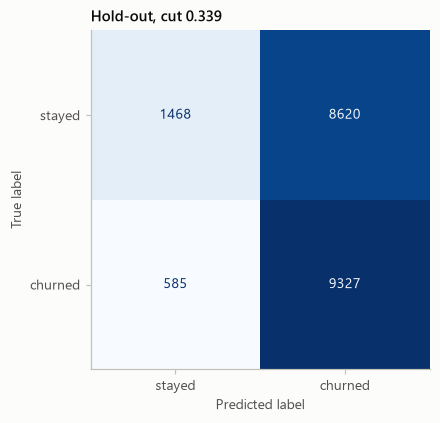

In [10]:
fig = ConfusionMatrixDisplay.from_predictions(y_test, proba >= threshold, display_labels=["stayed", "churned"],
                                              cmap="Blues", colorbar=False).figure_
fig.axes[0].set_title(f"Hold-out, cut {threshold:.3f}")
fig.set_size_inches(4.5, 4)

**Takeaway:** on the 20,000 hold-out customers the model scores **ROC-AUC 0.645**, PR-AUC 0.633 and log-loss 0.660, the same as in CV (0.644). There is no overfitting, and the cut chosen on the training folds carries over.
- At the cut 0.339: **recall 0.94, precision 0.52, F1 0.67**. The model flags 17,947 customers (90%). It reaches 9,327 of the 9,912 churners and misses 585, but 8,620 of the 10,088 stayers would be contacted too.
- At 0.5 the same model has precision 0.61, recall 0.58 and F1 0.59. The cut trades precision for recall; it does not make the model better, since the ranking (ROC-AUC) is the same at every cut.

## Conclusions

**Results** (5-fold CV on the training set; hold-out scored once)
1. An elastic-net logistic regression on every variable, with C and l1_ratio chosen by CV log-loss, reaches **ROC-AUC 0.644 in CV and 0.645 on the hold-out**. The CV loss is flat for C from 0.1 to 100: regularisation does not help at this sample size, and the chosen model keeps all 197 columns.
2. The 7 engineered ratios are strong alone (two would be MI #2 of 97) but add little to a linear model: +0.0003 ROC-AUC for the scale-free ratios and +0.0009 ± 0.0003 for the trend ratios.
3. At the F1-best cut (0.339): recall 0.94, precision 0.52, F1 0.67, with 90% of customers flagged.

**What the coefficients say** (association at equal values of the other variables, not causation)
- Falling usage, more subscribers than active lines, an old and cheap handset, voice overage and dropped calls go with churn.
- Near-duplicate usage variables offset each other: read the usage family as one driver, not its coefficients one by one.

**Why a linear model is not enough**
- The two strongest signals in the data are shapes: a peak at 11–12 months of tenure and a step at ~300 days of handset age. A straight line on the signed-log scale draws neither.
- Usage effects that are steep on one side and flat on the other get flattened.
- That information is lost. `03_xgboost` uses a model that learns the shapes.